# chip_06_test_cyro_tlq — 24 HSQ trilayer junction test pads for cryogenic probing, on the Quantcore PDK

## 1 · What the chip is

**Source:** `components/python/chip_06_test_cyro_TLQ.py` (`create_test_chip()`, writes `chip_06_test_cryoTLQ_1.0.gds`),
Quantcore internal. Spec: `docs/designs/legacy/chip_06_test_cyro_tlq.md`.

A 7.5 × 7.5 mm die holding a 6 × 4 array of `testPad_Nb_TL_HSQ` probe structures (two 500 × 400 µm pads across a
300 µm gap, an HSQ-spacer trilayer junction between the tips) with the straight finger swept 0.4 … 0.9 µm along the
columns and a 0.6 µm bent finger; 24 wire-bond rings (800 µm metal squares in a 100 µm etched ring) on the four
edges; HSQ corner markers (on the HSQ layer) beside the dicing markers. Column labels give the finger widths in
nm.

| | the rebuild keeps (source-faithful) | the Quantcore PDK changes |
|---|---|---|
| test pads, rings | the 24 `testPad_Nb_TL_HSQ` structures (`JunctionTestPads`) at the legacy positions and the 24 wire-bond rings (`TaperedPad`s: an 800 µm pad, no taper, in a 1000 µm window: the same etch, same size); the HSQ corner markers (`CornerMarker`, `hsq=True`) | the fingers valued on the PDK process, never resized |
| bond pads | — (the rings are probe / wire-bond rings drawn as `TaperedPad`s, flush with the die edge) | the rings follow the pad rule (decision, 2026-11-18): each ring's outer etch window sits `frame.pad_edge` = 100 µm from its die edge (was flush), at a 900 µm pitch (was 940), centred on the edge (steps 4–5) |
| cheese | — (the source has none) | the **PDK band** (3 rows of 5 µm squares, 20 µm gaps, around the 3/0 keep-outs; `cheese: "auto"`), drawn by the build and kept by the fab mask |
| placement | the legacy grid | centred in the die where > 50 µm off: already centred (step 7) |
| frame | — | the PDK die frame instead of the legacy base-metal corner `Marker`s and layer-10 outlines; the device ID `CHIP06` finds no free place (rings on every edge) and is omitted; the nm labels are not drawn |
| FEM | — | no sim groups: nothing to excite (steps 11–12 say so) |

**Reproduced exactly** (step 15): the 24 test pads at their legacy positions, XOR-identical to the legacy output (the rings are compared at their new, pad-rule positions); the HSQ markers (50 / 150 µm).

### Changes after design review (2026-11-03)

- **#1 junction values — PDK trilayer rule** (Nb, Δ = 1.4 meV, I_c·R_n = πΔ/2e = 2.20 mV, R_n 40–50 kΩ for the
  qubits): the drawn legacy test-pad fingers are kept (the sweep is the point of a test chip) and valued on the PDK
  process (R_n·A 13.5 kΩ·µm², C_J 50 fF/µm², both assumed by the PDK; 0.5 × 0.6 µm → 45 kΩ, L_J 6.73 nH; R_n ∝
  1/area). The earlier assumed J_c = 1 µA/µm² is gone. Values in step 10.
- **#16 device ID restored:** `name_chip="CHIP06"`. The bond rings line all four edges, so no edge centre is free;
  the frame's rule then tries beside the pads (50 µm gap), then slides along the left / right edge, and omits the ID
  if nothing is free (no DRC warning). On this chip the 24 rings leave no free block anywhere, so the build draws
  **no** ID; `name_chip` is set, so it appears if the rings move. (They moved 100 µm in on 2026-11-18, to the pad
  rule, but still line every edge: still no ID.)

### PDK conformance pass (notebooks-legacy, 2026-11-18)

- **Pads (decision, 2026-11-18):** the 24 wire-bond rings follow the pad rule. Each ring's outer etch window now
  sits `frame.pad_edge` = 100 µm from its die edge (before: flush with the edge). The ring size is kept; the pitch
  along each edge is 900 µm (before: 940), centred. The probe pads of the test structures are not bond pads and keep
  their legacy positions. The library's `pad_edge` DRC and `C.pads_md(d)` only know the launcher cells, so step 7 checks
  the rings with its own printout.
- **Centring:** `L.center_circuit` (each axis only if > 50 µm off): shift (0, 0): the legacy grid is already centred.
- **Cheese:** the source has none, so the PDK band applies (`cheese: "auto"`), drawn by the build and kept by the
  fab mask.
- **Junctions:** the legacy fingers, valued on the PDK process; `pdk_rn` flags a junction outside 40–50 kΩ (only
  cells that carry lumped junction values are checked), never retuned.
- **No FEM groups** (nothing to excite): steps 11 and 12 say so.
- Educative layout: one step per stage; the steps that do not apply to a test chip (pads, routes, FEM) say so.

## 2 · Setup and the Quantcore PDK

The helpers keep the cells short: `_common` (`C`) holds the netlist / LOM / FEM-export / snapshot helpers and
the PDK checks shared by every design notebook; `_legacy` (`L`) maps the legacy PCell parameters onto the
Quantcore cells, draws the legacy reference with the author's own legacy code (read-only), and holds the step
helpers of these notebooks. `LIVE` decides whether the design is pushed to a running KLayout (`QCC_LIVE=0`
for batch runs: nothing reaches KLayout).

In [1]:
%config InlineBackend.figure_formats = ["png"]
import os, sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
os.chdir(ROOT)                                       # paths below are relative to the repo root
sys.path.insert(0, str(ROOT / "examples" / "designs"))
sys.path.insert(0, str(ROOT / "examples" / "designs" / "legacy"))
LIVE = os.environ.get("QCC_LIVE", "1") == "1"       # live KLayout by default; QCC_LIVE=0 for batch runs
import _common as C                                  # netlist / LOM / FEM-export / snapshot / PDK-check helpers
import _legacy as L                                  # legacy frame shift, parameter mapping, legacy reference, steps
from quantcore_circuits.assembly.drc import device_id_block
from quantcore_circuits.layouts.others.test_pads import legacy_test_pad_params
from IPython.display import Image, Markdown, display
from quantcore_circuits.designer import Designer
from quantcore_circuits.pdk import get_pdk

ID, OUT = "chip_06_test_cyro_tlq", Path("examples/designs/legacy")

The PDK facts this rebuild uses, read from `get_pdk()` (nothing below is typed in by hand). The rules that
change a legacy chip are the **pad rule** (step 4), the **junction rule** (step 5), the **3/0 keep-out**
and the **cheese rule** (drawn by the build, step 14) and the centring of the content (step 7).

In [2]:
CHEESE_NOTE = 'PDK band (auto) — the source has no cheese of its own'
display(Markdown(L.pdk_facts_md(CHEESE_NOTE)))

| PDK item | value |
|---|---|
| PDK | `quantcore_nb_sapphire_v1` (version 3) |
| stack | sapphire, 650 µm, ε_r 10.25; Nb film (sheet metal in the FEM exports, 0.2 µm for the analytic CPW formulas) |
| CPW default | 10 µm centre, 6 µm gap, bends r = 100 µm |
| die frame | L-shaped dicing markers 25 µm wide (250 µm legs, 1000/0), 3 × 3 alignment grids (1001/0) in 500 µm corner squares, design area 100 µm inside the die edge, device ID optional (bottom centre, or beside the pads) |
| pad rule | bond pads / launchers: outer etch edge **100 µm** (the design-area margin) from the die edge, whatever the original did (`edge="auto"`, DRC design warning `pad_edge`) |
| junction rule | Nb/AlOx/Nb trilayer, Δ = 1.4 meV (I_c·R_n = πΔ/2e), R_n 40–50 kΩ (nominal 45), qubits 4–8 GHz; R_n·A 13500 Ω·µm² and C_J 50 fF/µm² assumed; cells `Quantcore Junction` / `Quantcore Squid` (DRC design warnings `pdk_rn`, `pdk_fq`: flagged, never retuned) |
| 3/0 keep-out | second-metal etch: routes + 10 µm, components' etch bbox + 24 µm, other 1/0 shapes + 9 µm (filled) |
| cheese rule | 3 rows of 5 µm squares, 20 µm gaps, in a band around the 3/0 keep-outs; **the original design's own cheese wins** (chip `cheese`: `"auto"` / `"pdk"` / `"original"`). This chip: PDK band (auto) — the source has no cheese of its own |

### The source's numbers (and the rings' new positions)

`chip_06_test_cyro_TLQ.py`'s numbers in its own (0, 0)-centred frame (µm): the finger sweep, the legacy
`np.linspace` grids of the pads and of the rings. `legacy_test_pad_params("testPad_Nb_TL_HSQ", bf / 0.2, tf)`: straight
finger `0.2·size` = bf, bent finger tf. `RING` draws the legacy `wirepad` (Box(1000) − Box(800)) as a `TaperedPad`. The source puts the ring windows flush
with the die edge; here they follow the PDK pad rule (see step 4), so `RING_Y` and `RING_X` are the rebuild's values.

In [3]:
# chip_06_test_cyro_TLQ.py, legacy frame (µm)
BOTTOM_FINGER = [0.4, 0.5, 0.6, 0.7, 0.8, 0.9]      # per column: create_testPad(bf / 0.2, tf)
TOP_FINGER = [0.6, 0.6, 0.6, 0.6]                   # per row (top_finger = [0.6] * 5, four rows used)
X = [-2200 + 880 * i for i in range(6)]             # np.linspace(-2500 + 300, 2500 - 300, 6)
Y = [-1950 + 1300 * j for j in range(4)]            # np.linspace(-2500 + 550, 2500 - 550, 4)
PAD_EDGE = get_pdk().frame.pad_edge                 # PDK pad rule: outer etch edge 100 µm from the die edge
RING_Y = 7500 / 2 - 1000 / 2 - PAD_EDGE             # ring centre: 1000 µm window (800 µm pad + 100 µm ring) at the rule
RING_X = [-2250 + 900 * k for k in range(6)]        # 6 rings per edge, centred; pitch 900 = pad 800 + one 100 µm ring
# (the source: RING_Y 3250 = flush with the die edge, RING_X = np.linspace(-2350, 2350, 6): pitch 940)
SCRIPT = "testPad_Nb_TL_HSQ"
params = [legacy_test_pad_params(SCRIPT, bf / 0.2, tf) for bf in BOTTOM_FINGER for tf in TOP_FINGER]
shared = {k: v for k, v in params[0].items() if k not in ("finger_width", "second_finger_width")}
RING = dict(pad_width=800, pad_height=800, conn_height=0.001, finger_width=800, negative=True,
            window_width=1000, window_height=1000, x=0, y=100)   # window − pad = the legacy 100 µm ring
rings = [(x, RING_Y) for x in RING_X] + [(x, -RING_Y) for x in RING_X] \
      + [(RING_Y, x) for x in RING_X] + [(-RING_Y, x) for x in RING_X]

## 3 · The die and the frame

`Designer(ID, box=...)` starts an empty 7.5 × 7.5 mm die (the PDK standard die). The PDK frame is drawn on every
build: four L-shaped dicing markers (1000/0), the 3 × 3 alignment grids (1001/0), the chip boundary (100/0) and the
device ID `CHIP06` (`name_chip`; optional: the frame places it where it is free). The chip parameter
`cheese` is left at `"auto"`: the source has no cheese, so the build draws the PDK band (visible from step 5 on).

(0.0, 0.0, 7500.0, 7500.0) quantcore_nb_sapphire_v1


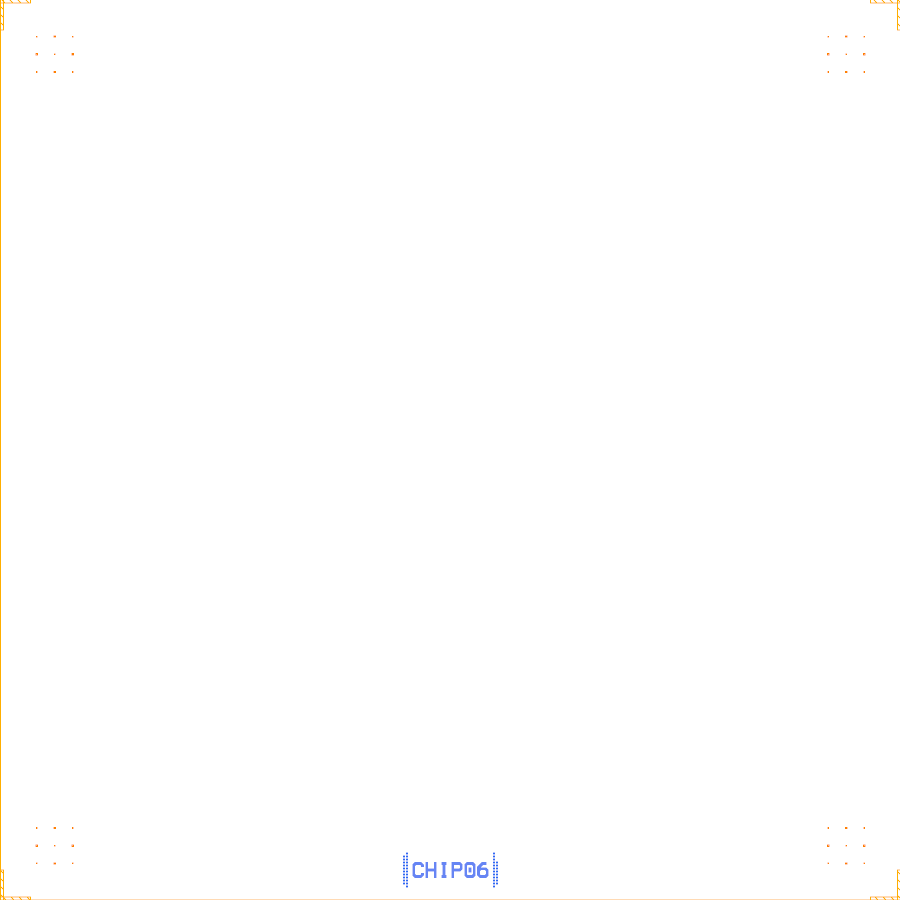

WindowsPath('build/legacy_steps/chip_06_test_cyro_tlq_1_frame.png')

In [4]:
d = Designer(ID, box=(0, 0, L.W, L.H), chip={"name_chip": "CHIP06"}, live=LIVE)   # cheese "auto"
print(d.design.chip.box, d.design.pdk)
L.step_snapshot(d, "1_frame")

## 4 · Pads (PDK pad rule): the wire-bond rings

The PDK pad rule puts every bond pad / launcher with its outer etch `frame.pad_edge` = 100 µm from the die edge
(`edge="auto"`). The 24 wire-bond rings of this chip are `TaperedPad`s, which the library counts as bond pads (since
2026-11-18: the `pad_edge` DRC checks them and `C.pads_md` lists them); the source draws them flush with the die edge. **It was decided
(2026-11-18) that they follow the rule.** So, in step 2's source numbers:
- **Distance:** `RING_Y` = 3750 − 500 − `frame.pad_edge` = 3150 µm from the die centre: the 1000 µm window's outer edge
  is 100 µm from the die edge (was 0).
- **Size:** unchanged, an 800 µm pad in a 1000 µm window.
- **Pitch along an edge:** 900 µm (was 940), six rings centred on the edge: centres at −2250 … +2250 µm. 900 µm is
  the 800 µm pad plus one 100 µm ring, so neighbouring windows overlap by exactly one ring width (100 µm; was 60 µm),
  share that ring, and no window cuts into a neighbour's pad. A larger pitch would not work: the end ring's window
  would then cut into the pad of the end ring on the next edge, now that the rings sit 100 µm further in. The outer
  windows end 2750 µm from the die centre, clear of the 500 µm corner areas (dicing markers, alignment grids, HSQ markers).
- **Test pads:** the `JunctionTestPads` array spans ±2500 µm; the nearest ring windows start at ±2650 µm, so the etch
  clearance is 150 µm (250 µm to a ring's pad). The array stays where the source put it.

Step 7 prints the measured distances.

## 5 · Components: the test structures

One `d.array` of `JunctionTestPads` (6 × 4, pitch 880 × 1300 µm, `vary` sets the two finger widths per pad), the 24
wire-bond rings at the pad-rule positions of step 4 (`TaperedPad`, its window starting at its origin, hence the −500 µm) and the four HSQ corner markers.
The test pads and markers have no ports; each ring's `finger` port is a bare pad node (nothing is routed to it).

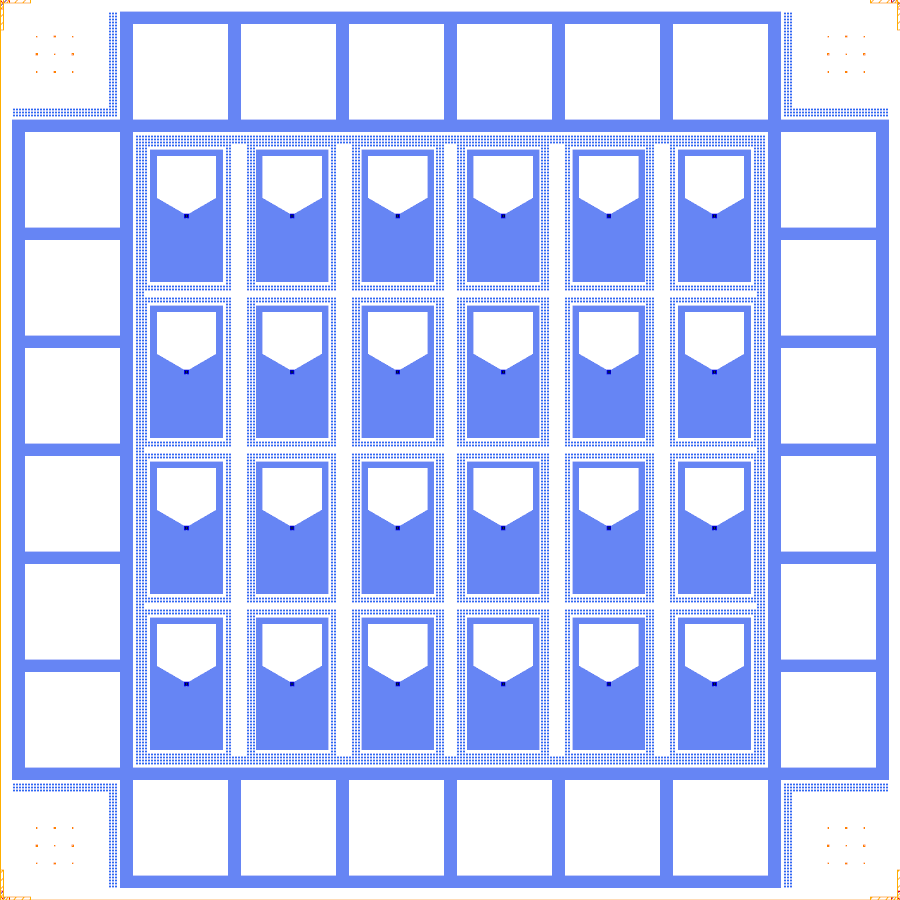

device ID block: False (False: no free place, omitted)


In [5]:
with d.batch():
    pads = d.array("TP", "JunctionTestPads", origin=L.at(X[0], Y[0]), pitch=(880, 1300), shape=(6, 4),
                   vary={"finger_width": [p["finger_width"] for p in params],
                         "second_finger_width": [p["second_finger_width"] for p in params]}, **shared)
    for k, (x, y) in enumerate(rings):
        d.add(f"WB{k}", "TaperedPad", **L.place(x, y - 500), **RING)       # TaperedPad window starts at its origin
    for k, (x, y, rot) in enumerate([(-3750, -3750, 1), (3750, -3750, 2), (3750, 3750, 3), (-3750, 3750, 0)]):
        d.add(f"HSQ{k}", "CornerMarker", **L.place(x, y, rot), hsq=True, thickness=50, width=150)
L.step_snapshot(d, "2_testpads")
print("device ID block:", device_id_block(d.result), "(False: no free place, omitted)")

## 6 · Routes: does not apply

No routes: the test structures are probed directly (needles or wire bonds on their own pads), nothing is wired on
chip.

## 7 · Cheese, pads check and centring

**Cheese.** The source has no cheese, so the build draws the **PDK band** (`cheese: "auto"`): 3 rows of 5 µm squares
with 20 µm gaps around the 3/0 keep-outs, at least 4 µm from 3/0, never over empty ground (visible in the snapshots
as the dotted rings around each structure).

**Centring (PDK placement rule).** `L.center_circuit` measures the circuit (instances, free text labels left out) and
shifts the design so it sits in the middle of the die, each axis only if it is more than 50 µm off. Then the design
is saved. A printout measures each ring's outer window edge against the pad rule (`C.pads_md(d)` gives the same
distances: it counts the `TaperedPad` rings as bond pads since 2026-11-18).

centring shift (µm): (0.0, 0.0) | <Designer chip_06_test_cyro_tlq: 52 instances, 0 routes, live=False> → examples\designs\legacy\chip_06_test_cyro_tlq.json


| pad | cell / launcher | nearest die edge | outer etch → die edge (µm) | PDK rule |
|---|---|---|---|---|
| – | no bond pads or launchers | – | – | – |

24 rings: outer window edge 100 … 100 µm from the die edge (PDK pad_edge 100 µm)


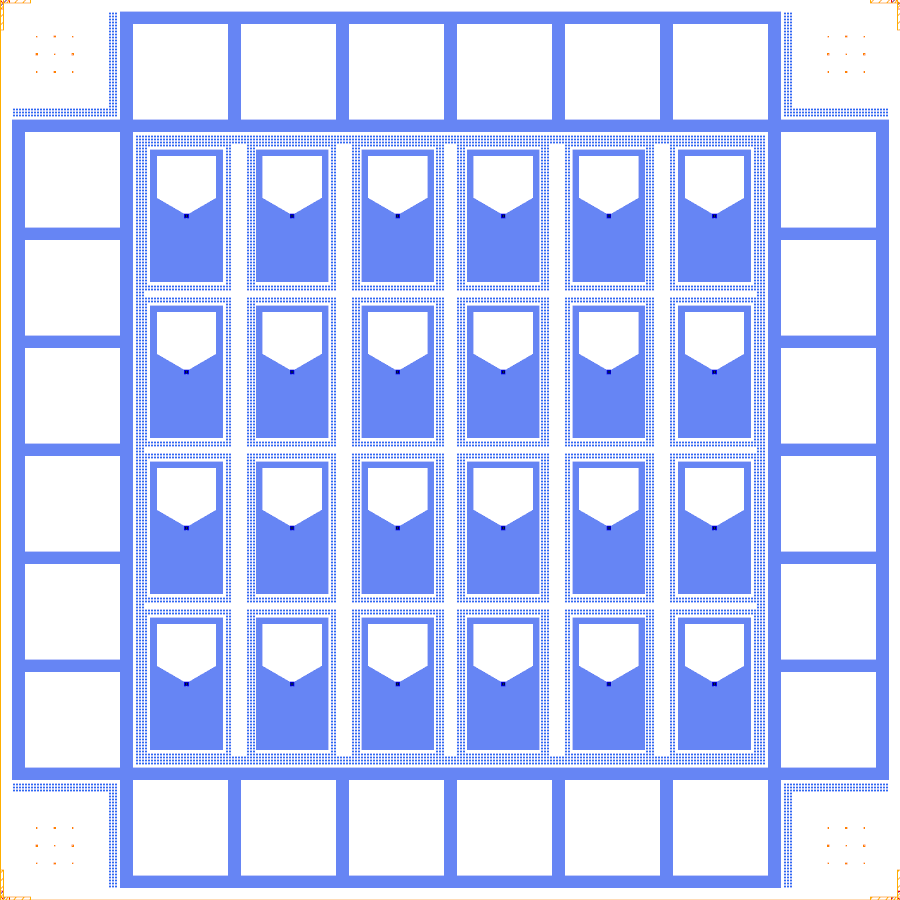

WindowsPath('build/legacy_steps/chip_06_test_cyro_tlq_3_centred.png')

In [6]:
SHIFT = L.center_circuit(d)
DESIGN = d.save(OUT / f"{ID}.json")
print("centring shift (µm):", SHIFT, "|", d, "→", DESIGN)
display(Markdown(C.pads_md(d)))
from quantcore_circuits.assembly import build
from quantcore_circuits.assembly.sidecar import sidecar_dict
x0, y0, x1, y1 = d.design.chip.box
boxes = [sidecar_dict(build(d.design), overlays=False)["instances"][f"WB{k}"]["bbox"] for k in range(24)]
gaps = [min(b[0] - x0, b[1] - y0, x1 - b[2], y1 - b[3]) for b in boxes]
print(f"24 rings: outer window edge {min(gaps):g} … {max(gaps):g} µm from the die edge (PDK pad_edge {PAD_EDGE:g} µm)")
L.step_snapshot(d, "3_centred")

## 8 · DRC

`d.drc()` builds the chip and checks it: **errors** (overlapping etch of unrelated cells, ports not landing,
parts outside the chip, a route looping over itself or running over a component) must be fixed; **warnings** are
reported for a person to judge (a dangling open end, two cells' bounding boxes touching); **PDK design warnings**
(`pad_edge`, `pdk_rn`, `pdk_fq`, `pdk_claw`) flag values outside the PDK margins — they are never retuned for, only
listed. `C.pdk_report(d)` summarises the PDK checks: cheese source, content centring (free text labels left out),
junction types and the design warnings.

Expected (this run): zero errors. Warnings, all from the legacy layout kept as drawn: `dangling_port` `WB0.finger` …
`WB23.finger` (24: the wire-bond rings are pads, nothing is routed to them); `overlap` WBk / WBk+1 (24, as before: neighbouring
1000 µm ring windows at the new 900 µm pitch overlap by 100 µm, one ring width (60 µm at the legacy 940 µm), and the
end rings of adjacent edges by 100 × 100 µm (as before); the rings merge there, as in the legacy chip); `frame_margin` / `frame_keepout` HSQ0–HSQ3 (8: the HSQ markers at the die corners, in
the dicing-marker areas, HSQ layer only). No PDK design warnings: the `pad_edge` check counts the rings as bond pads, and all 24 sit at 100 µm. **Device ID:** `CHIP06` finds no free block (rings on every edge), so the frame omits it (no
warning). Note: the outer ring windows are now 100 µm from the die edge (the pad rule, decision 2026-11-18; step 7
prints the measured distances). The DRC checks them (`pad_edge`, since 2026-11-18): all 24 at 100.0 µm, so no `pad_edge` warning. `pdk_report`: cheese "PDK band", content
centre (+0, +0) µm, junction types "—", 0 PDK design warnings.

In [7]:
drc = d.drc()
print(drc)
display(Markdown(C.pdk_report(d)))

warning dangling_port WB0.finger is not connected (no route or snap)
warning dangling_port WB1.finger is not connected (no route or snap)
warning dangling_port WB10.finger is not connected (no route or snap)
warning dangling_port WB11.finger is not connected (no route or snap)
warning dangling_port WB12.finger is not connected (no route or snap)
warning dangling_port WB13.finger is not connected (no route or snap)
warning dangling_port WB14.finger is not connected (no route or snap)
warning dangling_port WB15.finger is not connected (no route or snap)
warning dangling_port WB16.finger is not connected (no route or snap)
warning dangling_port WB17.finger is not connected (no route or snap)
warning dangling_port WB18.finger is not connected (no route or snap)
warning dangling_port WB19.finger is not connected (no route or snap)
warning dangling_port WB2.finger is not connected (no route or snap)
warning dangling_port WB20.finger is not connected (no route or snap)
warning dangling_port W

| check | value |
|---|---|
| cheese | PDK band (drawn in the build) |
| content centre − die centre | (+0, +0) µm |
| junction types | — |
| PDK design warnings | 0 (none) |

## 9 · Netlist and LOM

The test pads and HSQ markers are port-less. Each wire-bond ring is a `TaperedPad` whose `finger` port becomes a bare pad
node (24 nodes with only their pad C to ground, 24 unconnected ports: no circuit role).

In [8]:
lb = d.lom()
C.show_netlist(lb)
print(C.lom_summary(lb))

**25 nodes · 24 branches · 0 controls · 24 unconnected ports**

| node | FEM nets |
|---|---|
| `gnd` | ground |
| `WB0.pad` | `WB0.pad` |
| `WB1.pad` | `WB1.pad` |
| `WB2.pad` | `WB2.pad` |
| `WB3.pad` | `WB3.pad` |
| `WB4.pad` | `WB4.pad` |
| `WB5.pad` | `WB5.pad` |
| `WB6.pad` | `WB6.pad` |
| `WB7.pad` | `WB7.pad` |
| `WB8.pad` | `WB8.pad` |
| `WB9.pad` | `WB9.pad` |
| `WB10.pad` | `WB10.pad` |
| `WB11.pad` | `WB11.pad` |
| `WB12.pad` | `WB12.pad` |
| `WB13.pad` | `WB13.pad` |
| `WB14.pad` | `WB14.pad` |
| `WB15.pad` | `WB15.pad` |
| `WB16.pad` | `WB16.pad` |
| `WB17.pad` | `WB17.pad` |
| `WB18.pad` | `WB18.pad` |
| `WB19.pad` | `WB19.pad` |
| `WB20.pad` | `WB20.pad` |
| `WB21.pad` | `WB21.pad` |
| `WB22.pad` | `WB22.pad` |
| `WB23.pad` | `WB23.pad` |

| branch | type | nodes | estimate |
|---|---|---|---|
| `C_WB0` | C | `WB0.pad` – `gnd` | 360 fF |
| `C_WB1` | C | `WB1.pad` – `gnd` | 360 fF |
| `C_WB2` | C | `WB2.pad` – `gnd` | 360 fF |
| `C_WB3` | C | `WB3.pad` – `gnd` | 360 fF |
| `C_WB4` | C | `WB4.pad` – `gnd` | 360 fF |
| `C_WB5` | C | `WB5.pad` – `gnd` | 360 fF |
| `C_WB6` | C | `WB6.pad` – `gnd` | 360 fF |
| `C_WB7` | C | `WB7.pad` – `gnd` | 360 fF |
| `C_WB8` | C | `WB8.pad` – `gnd` | 360 fF |
| `C_WB9` | C | `WB9.pad` – `gnd` | 360 fF |
| `C_WB10` | C | `WB10.pad` – `gnd` | 360 fF |
| `C_WB11` | C | `WB11.pad` – `gnd` | 360 fF |
| `C_WB12` | C | `WB12.pad` – `gnd` | 360 fF |
| `C_WB13` | C | `WB13.pad` – `gnd` | 360 fF |
| `C_WB14` | C | `WB14.pad` – `gnd` | 360 fF |
| `C_WB15` | C | `WB15.pad` – `gnd` | 360 fF |
| `C_WB16` | C | `WB16.pad` – `gnd` | 360 fF |
| `C_WB17` | C | `WB17.pad` – `gnd` | 360 fF |
| `C_WB18` | C | `WB18.pad` – `gnd` | 360 fF |
| `C_WB19` | C | `WB19.pad` – `gnd` | 360 fF |
| `C_WB20` | C | `WB20.pad` – `gnd` | 360 fF |
| `C_WB21` | C | `WB21.pad` – `gnd` | 360 fF |
| `C_WB22` | C | `WB22.pad` – `gnd` | 360 fF |
| `C_WB23` | C | `WB23.pad` – `gnd` | 360 fF |

**Unconnected ports:** `WB0.finger`, `WB1.finger`, `WB10.finger`, `WB11.finger`, `WB12.finger`, `WB13.finger`, `WB14.finger`, `WB15.finger`, `WB16.finger`, `WB17.finger`, `WB18.finger`, `WB19.finger`, `WB2.finger`, `WB20.finger`, `WB21.finger`, `WB22.finger`, `WB23.finger`, `WB3.finger`, `WB4.finger`, `WB5.finger`, `WB6.finger`, `WB7.finger`, `WB8.finger`, `WB9.finger`

{'nodes': 24, 'branches': 24, 'controls': 0, 'unconnected': 24}


## 10 · LOM simulation: does not apply — the junction table instead

A test-structure chip has no qubit or resonator to simulate; the junction values follow from the drawn finger
widths: area = straight × bent finger, R_n = (R_n·A) / area, L_J from Ambegaokar–Baratoff (`circuit.bridges`), on
the PDK junction rule.

In [9]:
display(Markdown(L.junction_grid(BOTTOM_FINGER, sorted(set(TOP_FINGER)),
                                 lambda bf, tf: (legacy_test_pad_params(SCRIPT, bf / 0.2, tf)["finger_width"], tf))))

L_J (nH) / R_n (kΩ) per test pad, drawn fingers on the PDK process. PDK junction rule: Nb trilayer, Δ = 1.4 meV → I_c·R_n = πΔ/2e = 2.199 mV; PDK process R_n·A = 13500 Ω·µm² (J_c = 0.163 µA/µm²; nominal 0.5 × 0.6 µm → 45 kΩ, L_J 6.73 nH), C_J = 50 fF/µm² (R_n·A and C_J assumed by the PDK). Area = straight × bent finger.

| top finger (µm) \ bottom finger (µm) | 0.4 | 0.5 | 0.6 | 0.7 | 0.8 | 0.9 |
|---|---|---|---|---|---|---|
| 0.6 | 8.42 / 56.2 | 6.73 / 45.0 | 5.61 / 37.5 | 4.81 / 32.1 | 4.21 / 28.1 | 3.74 / 25.0 |

**Reading the numbers** (this run): with the 0.6 µm bent finger the straight-finger sweep 0.4 … 0.9 µm gives R_n 56.2,
45.0, 37.5, 32.1, 28.1 and 25.0 kΩ: only the 0.5 µm column (45 kΩ, L_J 6.73 nH: the PDK nominal) lies in the
40–50 kΩ window.

## 11 · FEM: send the job — does not apply

A FEM job needs a sim group: a qubit / resonator cut-out with a port to excite. This chip has none (probe
structures only), so `C.export_sims(DESIGN)` exports nothing and `L.fem_send` says so. The cell stays so the
notebook has the same shape as the others (and `RUN_FEM` would have nothing to solve).

In [10]:
RUN_FEM = False                       # nothing to solve: the chip has no sim groups
jobs = C.export_sims(DESIGN)
display(Markdown(C.jobs_md(jobs) if jobs else "*no sim groups — nothing to export*"))
display(Markdown(L.fem_send(jobs, run=RUN_FEM)))

*no sim groups — nothing to export*

AEDT on this machine: `C:\Program Files\AnsysEM\v241\Win64\ansysedt.exe` (v241)

No FEM jobs: this chip has no sim groups (nothing to excite).

## 12 · Bring the results back — does not apply

No jobs, so no results to bring back (`L.fem_bring_back` says "No FEM jobs."). On a test chip the "results" are the
probe-station R_n values, compared with the junction table of step 10.

In [11]:
display(Markdown(L.fem_bring_back(d, DESIGN, jobs, groups=None)))

No FEM jobs.

## 13 · Iterate: change one property and rebuild

A copy gives the first pad (`TP_0_0`, 0.4 × 0.6 µm: 56 kΩ) a 0.5 µm straight finger, the PDK nominal junction
(0.5 × 0.6 µm, 45 kΩ), rebuilds it and checks it. The copy is not saved; the chip keeps the legacy sweep.

In [12]:
d2 = Designer.load(DESIGN, live=False, verbose=False)      # a copy of the saved design
p = dict(d2.data["instances"]["TP_0_0"]["params"])
d2["TP_0_0"].set(finger_width=0.5)
display(Markdown(L.junction_table([("TP_0_0 as drawn", p["finger_width"], p["second_finger_width"], 1),
                                   ("TP_0_0, straight finger 0.5 µm", 0.5, p["second_finger_width"], 1)])))
print("copy rebuilt:", d2.drc().ok, "(no DRC errors)")

PDK junction rule: Nb trilayer, Δ = 1.4 meV → I_c·R_n = πΔ/2e = 2.199 mV; PDK process R_n·A = 13500 Ω·µm² (J_c = 0.163 µA/µm²; nominal 0.5 × 0.6 µm → 45 kΩ, L_J 6.73 nH), C_J = 50 fF/µm² (R_n·A and C_J assumed by the PDK).

Drawn junctions (legacy fingers) on the PDK process:

| junction | fingers (µm) | n | area (µm²) | R_n (kΩ) | I_c (nA) | L_J (nH) | C_J (fF) |
|---|---|---|---|---|---|---|---|
| TP_0_0 as drawn | 0.4 × 0.6 | 1 | 0.2400 | 56.25 | 39.1 | 8.418 | 12.00 |
| TP_0_0, straight finger 0.5 µm | 0.5 × 0.6 | 1 | 0.3000 | 45.00 | 48.9 | 6.734 | 15.00 |

copy rebuilt: True (no DRC errors)


**Result** (this run): `TP_0_0` with a 0.5 µm straight finger: R_n 56.2 → 45.0 kΩ (L_J 8.42 → 6.73 nH); the copy
rebuilds without DRC errors.

## 14 · Build and export

The design is saved as JSON (`DESIGN`, step 7): it is the source of truth — the layout, the netlist, the
FEM jobs and the mask are all made from it. The **fab mask** (`export_fab`) keeps only the PDK fab layers
(1/0 etch, 2/0 + 4/0 junction fingers, 3/0 second-metal keep-out, 50–53/0 spacer, 100/0 boundary, 1000/0 +
1001/0 markers), rounds the corners (radius ∝ each polygon's shortest dimension) and keeps the build's
cheese; every cheese hole of 1/0 is also on 3/0. **Simulation exports** never carry cheese; they drop airbridges
unless asked (`build_simulation(..., airbridges=True)`); the legacy chips have none.

Here: `cheese=True` (the default): the build already carries the PDK band (the source has no cheese), so the mask
keeps it (`cheese_source` "build"), on 1/0 and on 3/0.

The same from a shell:

```
qcc build examples/designs/legacy/chip_06_test_cyro_tlq.json                    # layout → build/chip_06_test_cyro_tlq.oas
qcc mask  examples/designs/legacy/chip_06_test_cyro_tlq.json          # fab mask with the PDK rules
```

In [13]:
display(Markdown(L.fab_md(d)))

examples\designs\legacy\_legacy.py:747: FabLayersDropped: export_fab(chip_06_test_cyro_tlq): PDK quantcore_nb_sapphire_v1 has no fab layer for qcc hsq_boundary (150/0): 8 shape(s); not written
  path = export_fab(d.result, path or Path("build") / f"{d.design.name}_fab.oas", report=rep, cheese=cheese)


Fab mask: `build/chip_06_test_cyro_tlq_fab.oas` · cheese source **build** (10960 PDK-band holes) · corner rounding on

| fab layer | PDK name | polygons |
|---|---|---|
| 1/0 | M1 | 10985 |
| 2/0 | JJ_STRAIGHT | 24 |
| 3/0 | M3 | 10985 |
| 4/0 | JJ_BENT | 24 |
| 50/0 | HSQ | 52 |
| 51/0 | SPACER_1 | 48 |
| 52/0 | SPACER_2 | 48 |
| 53/0 | SPACER_3 | 48 |
| 100/0 | CHIP_BOUNDARY | 1 |
| 1000/0 | MARKERS_DICING | 4 |
| 1001/0 | MARKERS_ALIGN | 36 |

**Not in the mask (no PDK fab layer):** qcc hsq_boundary (150/0) (8)

## 15 · Snapshots and comparison with the legacy geometry

Full chip; one test pad (bf 0.4 µm); its junction with the HSQ spacer boxes; the lower-left corner with a ring, the PDK band and the HSQ marker.

Then the same chip drawn by the author's legacy scripts (run read-only through `tests/legacy_ref`, one
`testPad_Nb_TL_HSQ.create_testPad(bf / 0.2, tf)` per pad, the rings as the legacy `wirepad` regions at the rebuild's ring positions), moved by the
centring shift, and the etch XOR per legacy instance (PDK M1; slivers ≤ 2 nm ignored).

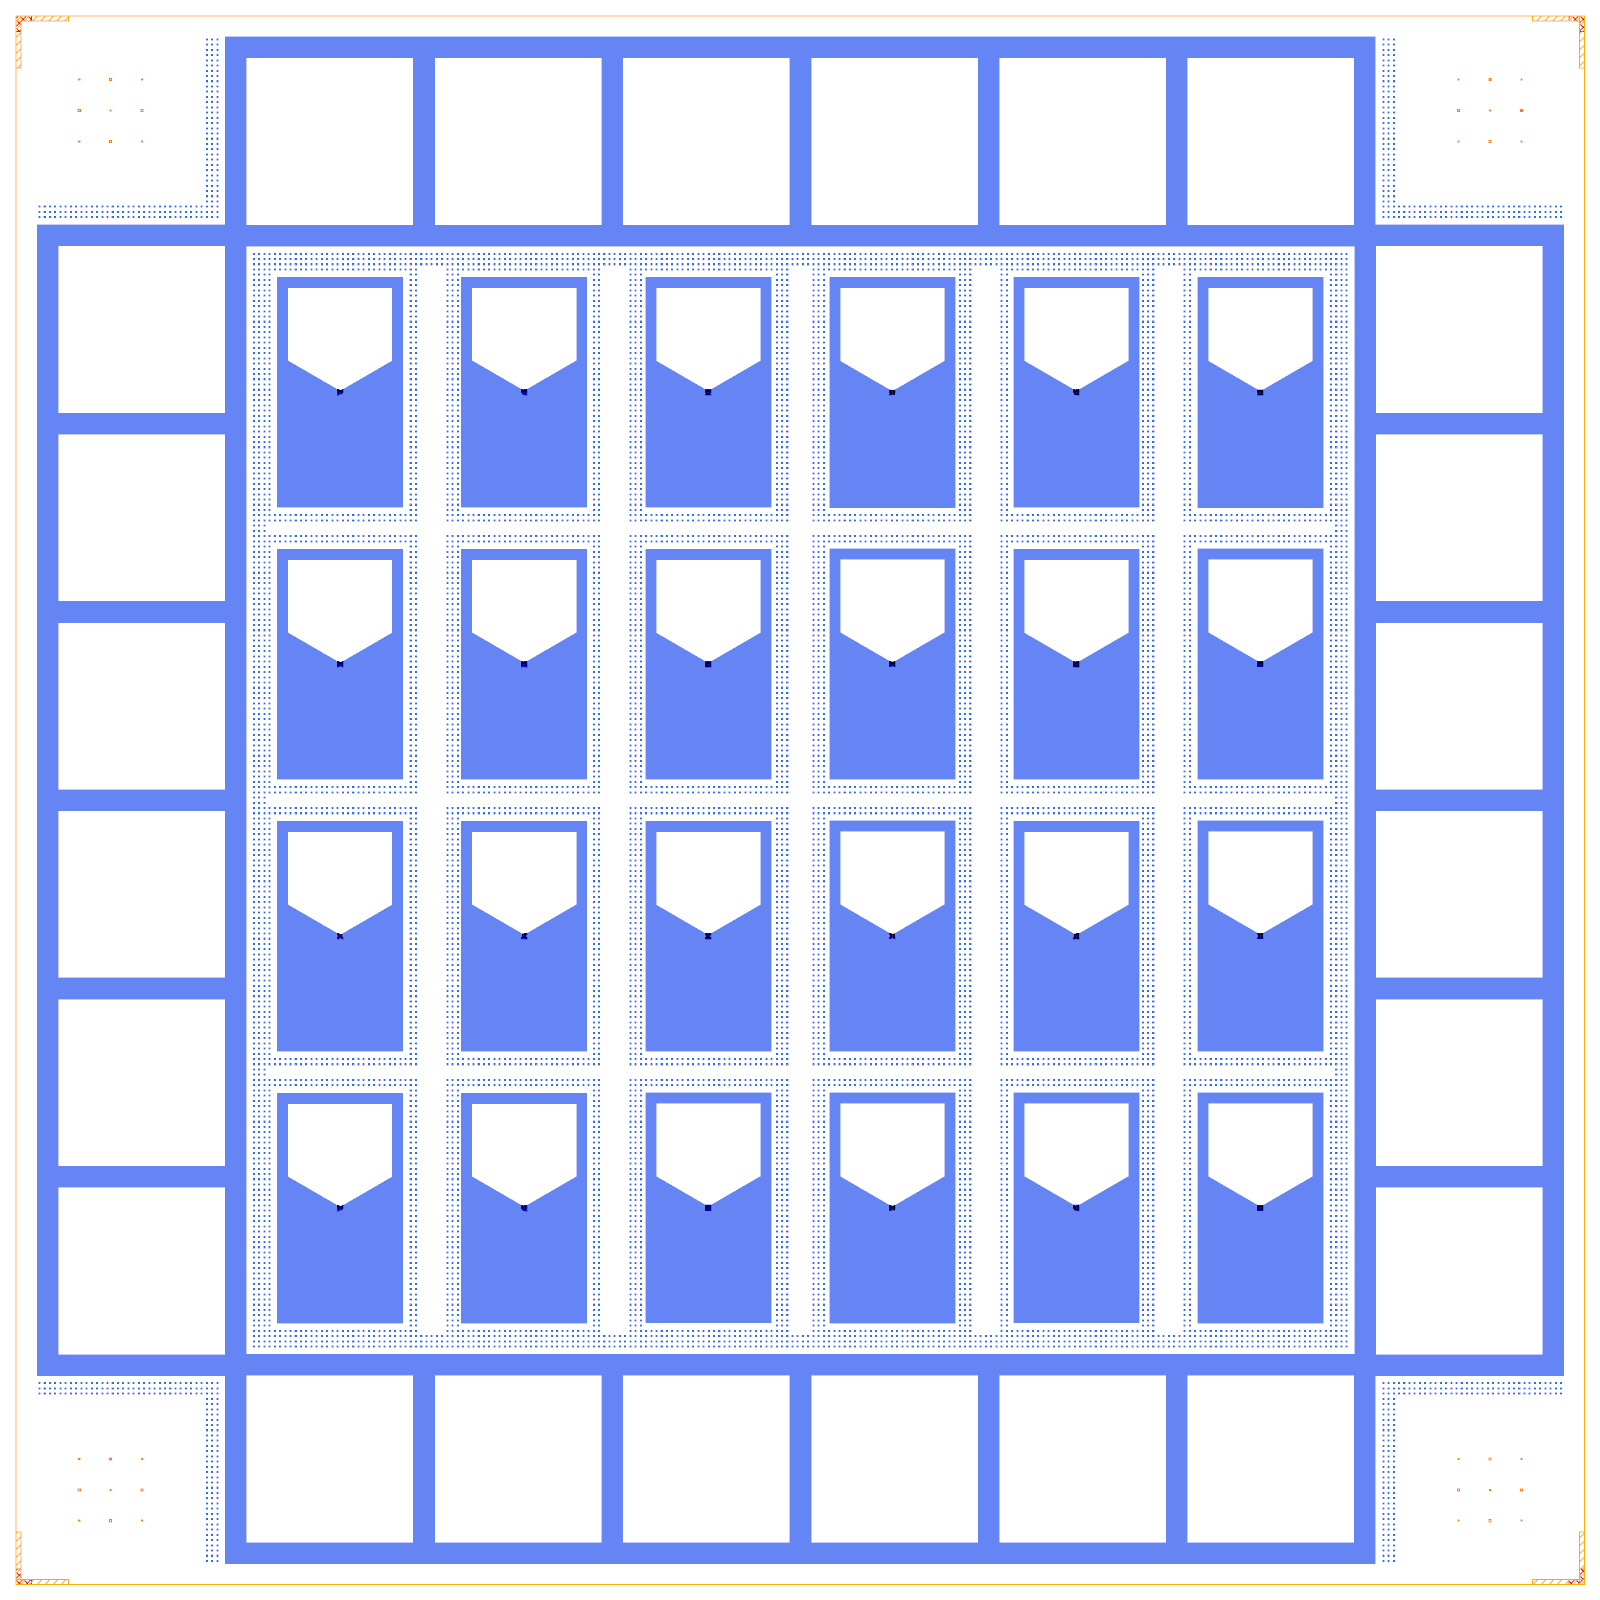

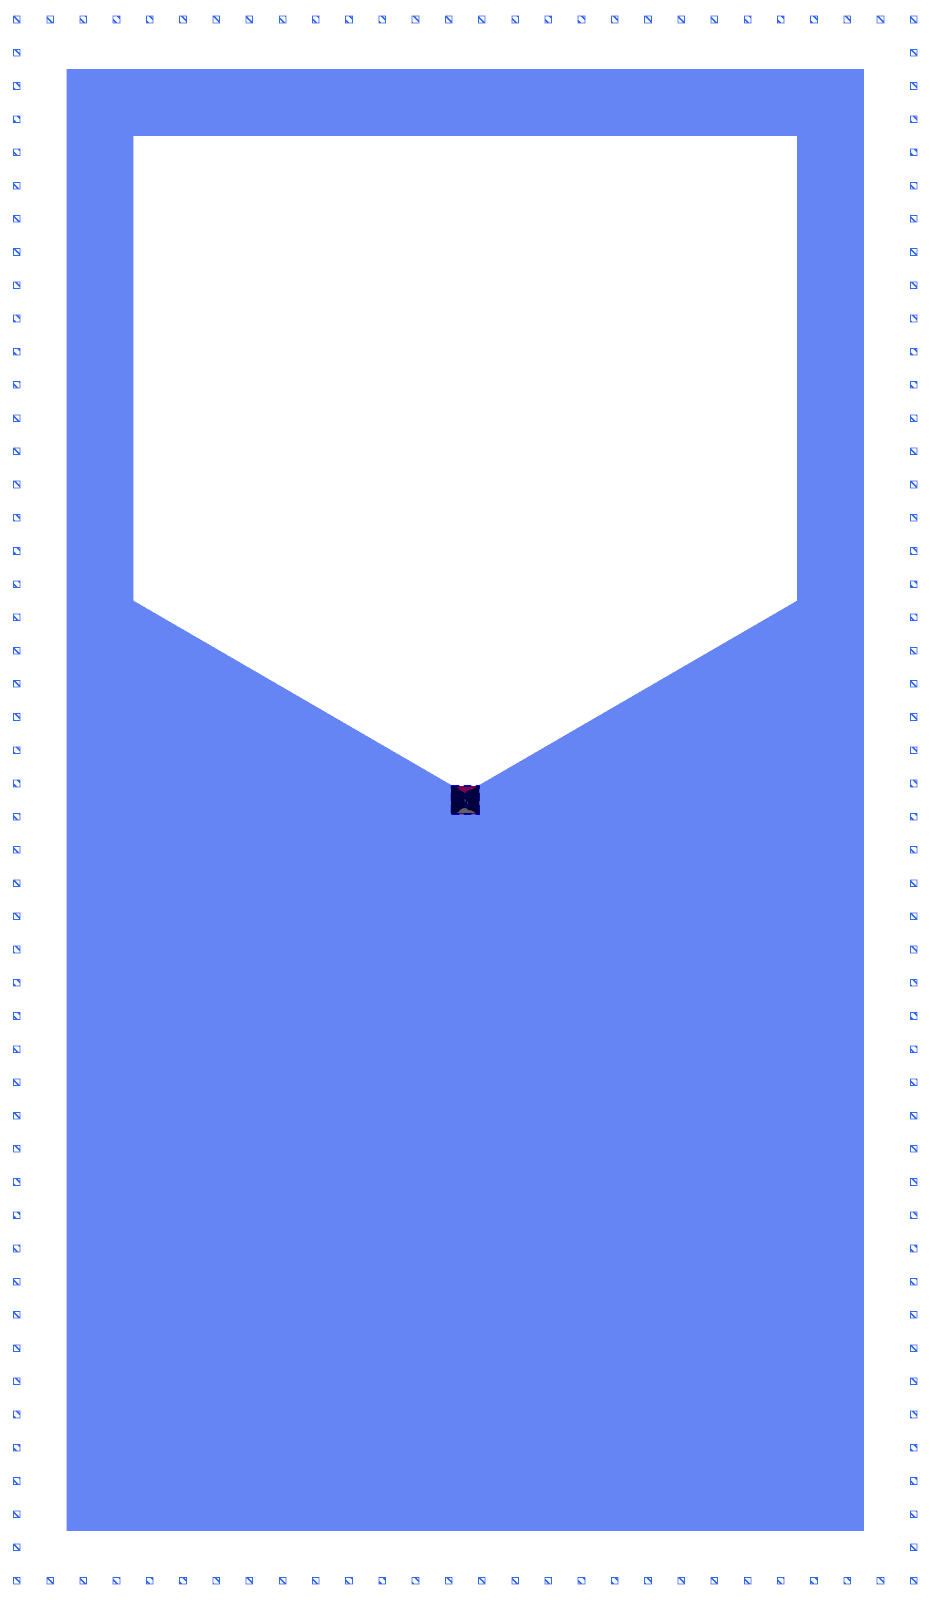

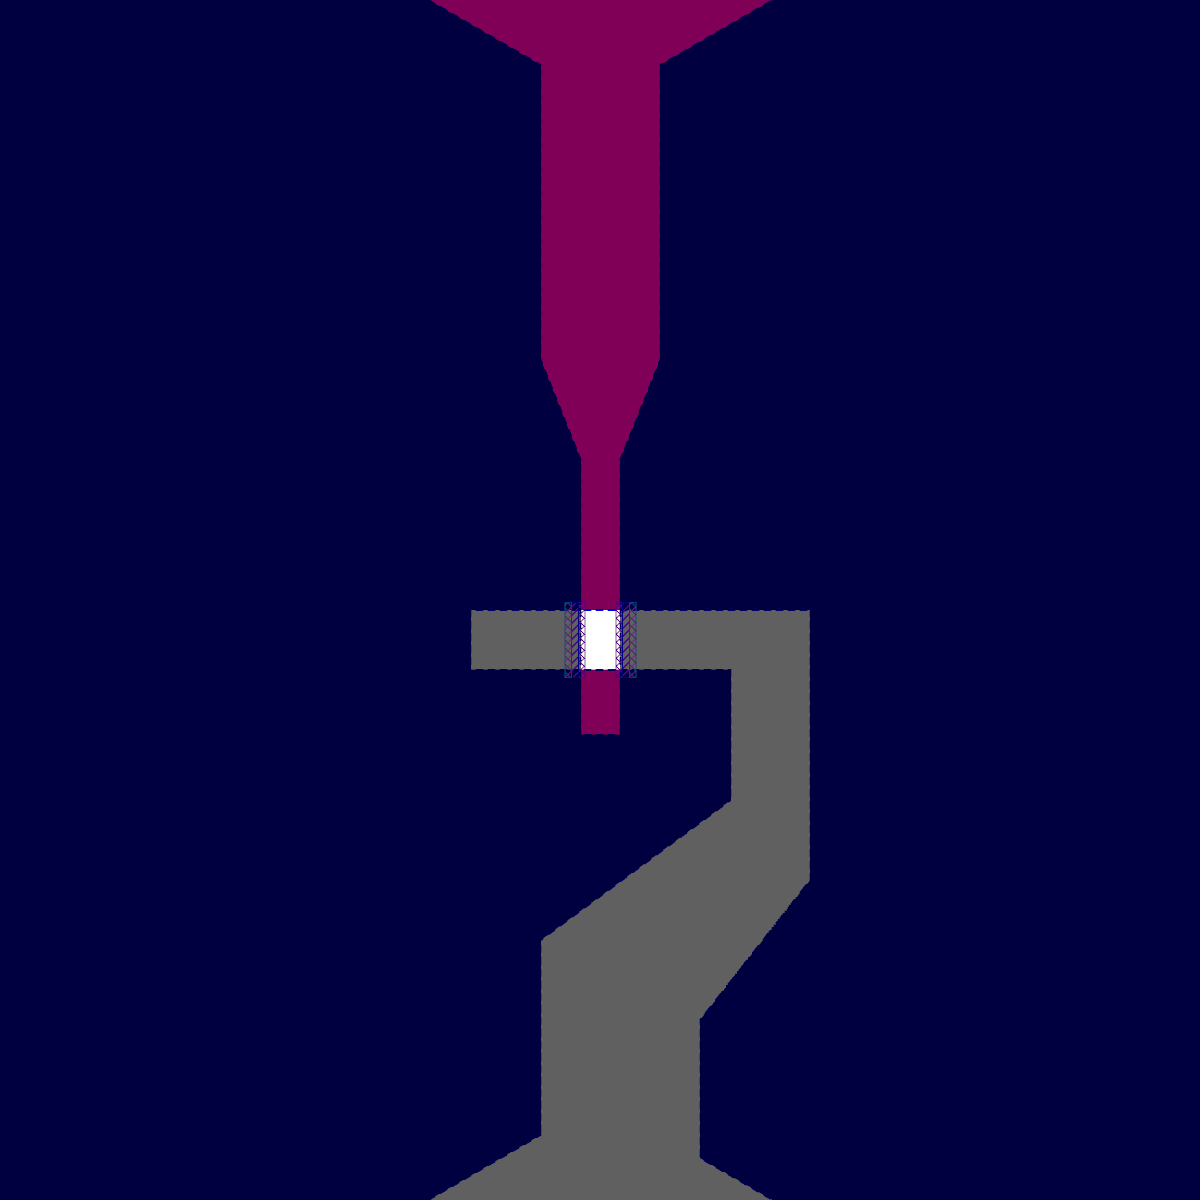

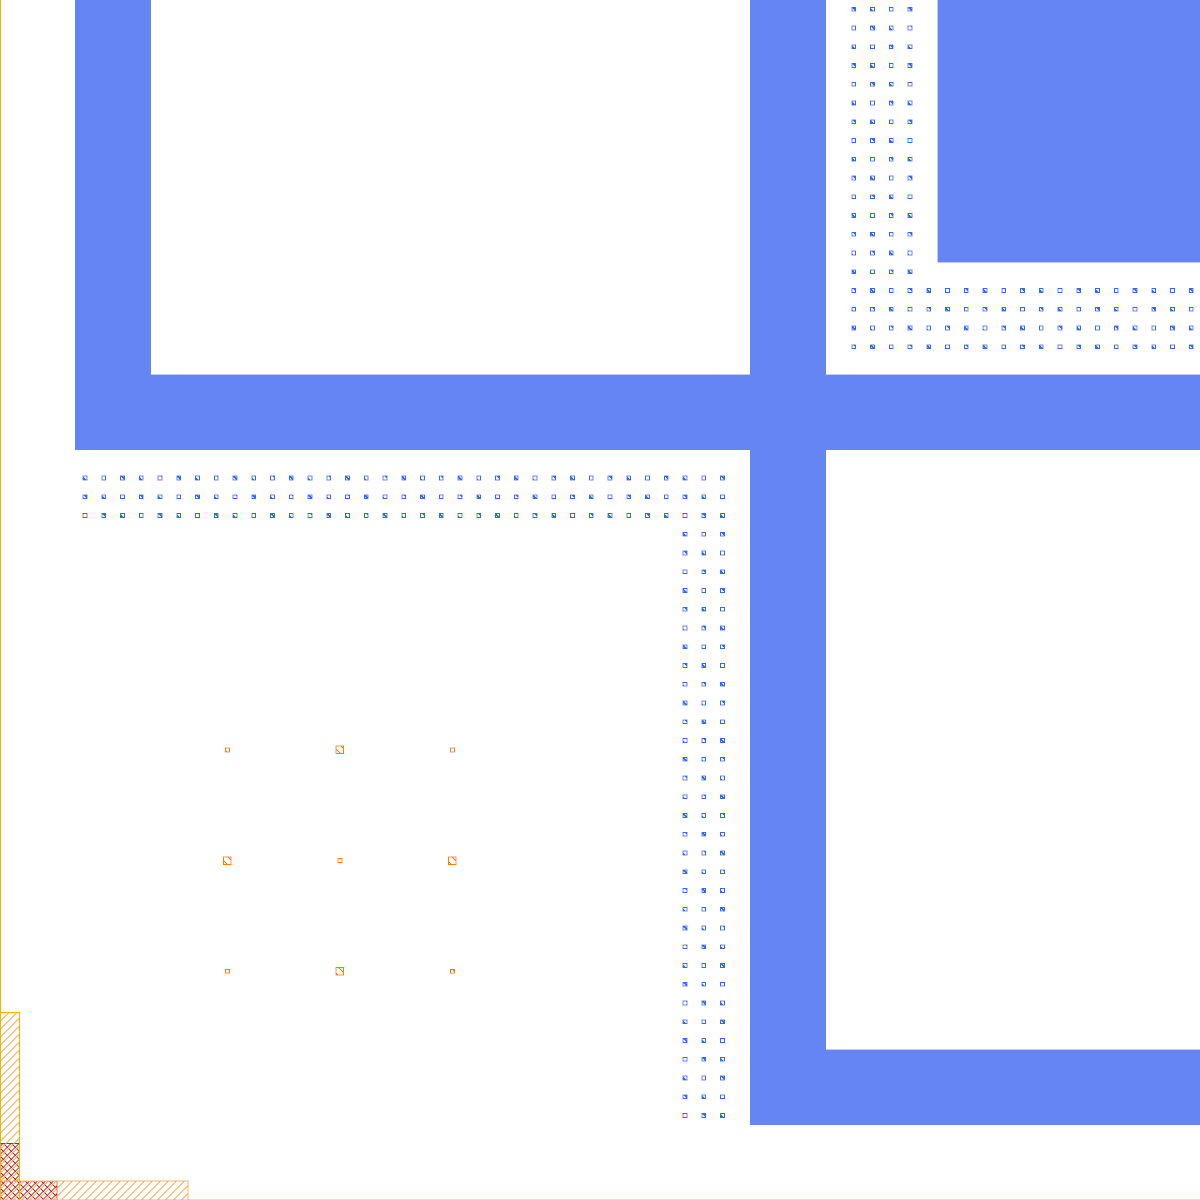

WindowsPath('examples/designs/legacy/chip_06_test_cyro_tlq_corner.png')

In [14]:
(x0, y0) = L.origin(d, "TP_0_0")
C.show_snapshot(d, OUT / f"{ID}.png")
C.show_snapshot(d, OUT / f"{ID}_pad.png", box=(x0 - 350, y0 - 600, x0 + 350, y0 + 600), size=(930, 1600), width=320)
C.show_snapshot(d, OUT / f"{ID}_jj.png", box=(x0 - 6, y0 - 6, x0 + 6, y0 + 6), size=(1200, 1200), width=360)
C.show_snapshot(d, OUT / f"{ID}_corner.png", box=(0, 0, 1600, 1600), size=(1200, 1200), width=360)

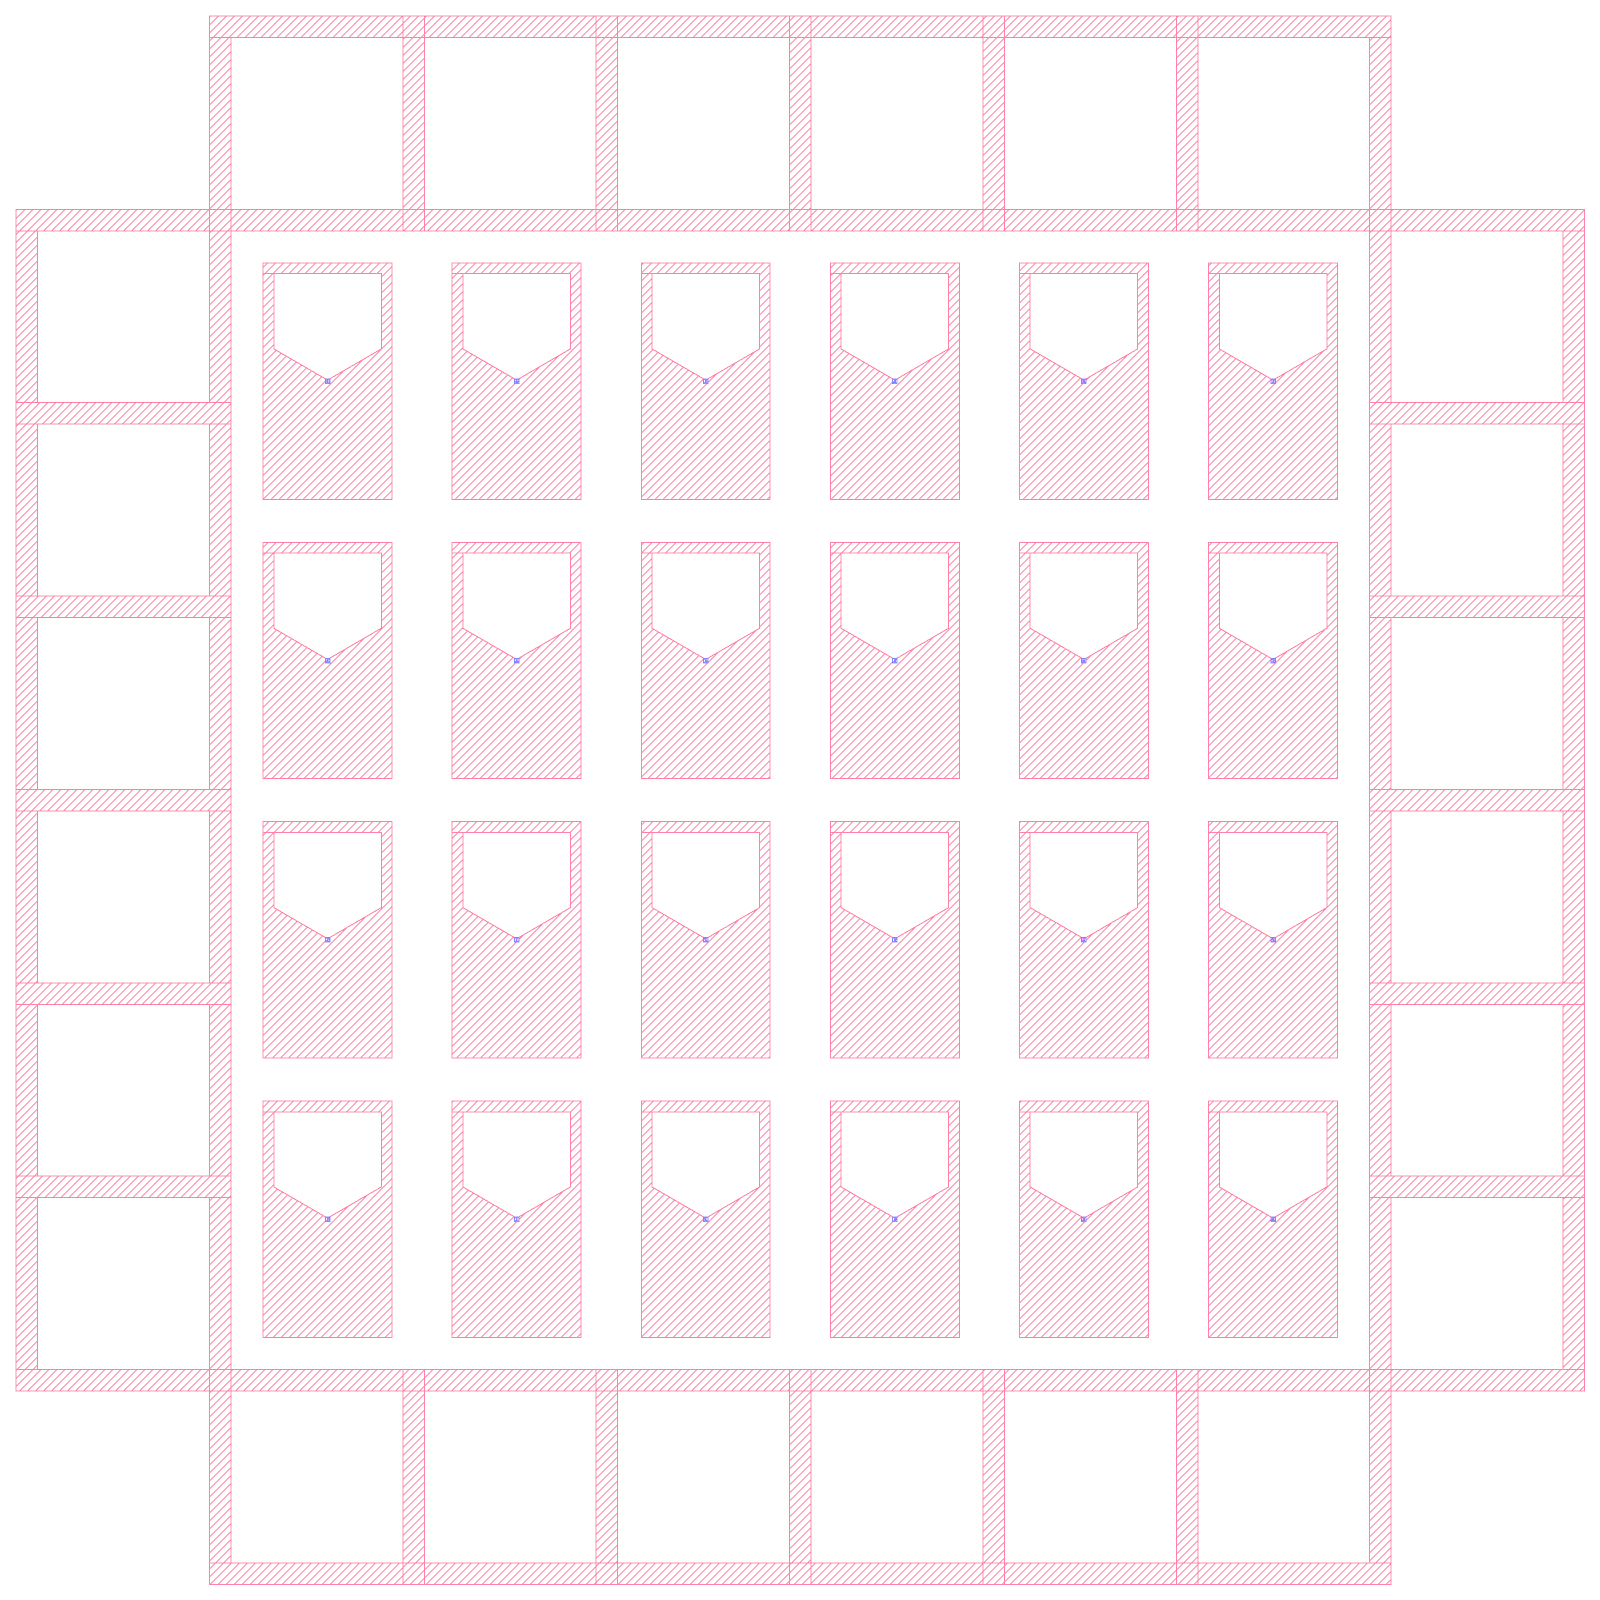

48 legacy instances: largest etch XOR 0.000 µm² (TP_0_0)


| instance | legacy etch (µm²) | rebuilt etch (µm²) | XOR (µm²) | XOR / legacy |
|---|---|---|---|---|
| TP_0_0 | 448393 | 448393 | 0.0 | 0.00% |
| TP_0_1 | 448393 | 448393 | 0.0 | 0.00% |
| TP_0_2 | 448393 | 448393 | 0.0 | 0.00% |
| TP_0_3 | 448393 | 448393 | 0.0 | 0.00% |
| TP_1_0 | 448393 | 448393 | 0.0 | 0.00% |
| TP_1_1 | 448393 | 448393 | 0.0 | 0.00% |
| TP_1_2 | 448393 | 448393 | 0.0 | 0.00% |
| TP_1_3 | 448393 | 448393 | 0.0 | 0.00% |
| TP_2_0 | 448393 | 448393 | 0.0 | 0.00% |
| TP_2_1 | 448393 | 448393 | 0.0 | 0.00% |
| TP_2_2 | 448393 | 448393 | 0.0 | 0.00% |
| TP_2_3 | 448393 | 448393 | 0.0 | 0.00% |
| TP_3_0 | 448393 | 448393 | 0.0 | 0.00% |
| TP_3_1 | 448393 | 448393 | 0.0 | 0.00% |
| TP_3_2 | 448393 | 448393 | 0.0 | 0.00% |
| TP_3_3 | 448393 | 448393 | 0.0 | 0.00% |
| TP_4_0 | 448393 | 448393 | 0.0 | 0.00% |
| TP_4_1 | 448393 | 448393 | 0.0 | 0.00% |
| TP_4_2 | 448393 | 448393 | 0.0 | 0.00% |
| TP_4_3 | 448393 | 448393 | 0.0 | 0.00% |
| TP_5_0 | 448393 | 448393 | 0.0 | 0.00% |
| TP_5_1 | 448393 | 448393 | 0.0 | 0.00% |
| TP_5_2 | 448393 | 448393 | 0.0 | 0.00% |
| TP_5_3 | 448393 | 448393 | 0.0 | 0.00% |
| WB0 | 360000 | 359999 | 0.0 | 0.00% |
| WB1 | 360000 | 359999 | 0.0 | 0.00% |
| WB2 | 360000 | 359999 | 0.0 | 0.00% |
| WB3 | 360000 | 359999 | 0.0 | 0.00% |
| WB4 | 360000 | 359999 | 0.0 | 0.00% |
| WB5 | 360000 | 359999 | 0.0 | 0.00% |
| WB6 | 360000 | 359999 | 0.0 | 0.00% |
| WB7 | 360000 | 359999 | 0.0 | 0.00% |
| WB8 | 360000 | 359999 | 0.0 | 0.00% |
| WB9 | 360000 | 359999 | 0.0 | 0.00% |
| WB10 | 360000 | 359999 | 0.0 | 0.00% |
| WB11 | 360000 | 359999 | 0.0 | 0.00% |
| WB12 | 360000 | 360000 | 0.0 | 0.00% |
| WB13 | 360000 | 360000 | 0.0 | 0.00% |
| WB14 | 360000 | 360000 | 0.0 | 0.00% |
| WB15 | 360000 | 360000 | 0.0 | 0.00% |
| WB16 | 360000 | 360000 | 0.0 | 0.00% |
| WB17 | 360000 | 359999 | 0.0 | 0.00% |
| WB18 | 360000 | 360000 | 0.0 | 0.00% |
| WB19 | 360000 | 360000 | 0.0 | 0.00% |
| WB20 | 360000 | 360000 | 0.0 | 0.00% |
| WB21 | 360000 | 360000 | 0.0 | 0.00% |
| WB22 | 360000 | 360000 | 0.0 | 0.00% |
| WB23 | 360000 | 359999 | 0.0 | 0.00% |

In [15]:
if L.legacy_available():
    ref = L.LegacyChip(ID)
    for i, bf in enumerate(BOTTOM_FINGER):
        for j, tf in enumerate(TOP_FINGER):
            cell = L.legacy_script_cell(SCRIPT + ".py", "create_testPad", "TEST_TL", bf / 0.2, tf,
                                        tmp=f"build/legacy_a/chip_06/{i}_{j}")
            ref.cell_from(f"TP_{i}_{j}", *cell, X[i], Y[j])
    for k, (x, y) in enumerate(rings):   # wirepad = Box(1000) − Box(800), as four strips
        ref.etch(f"WB{k}", [(x - 500, y - 500, x + 500, y - 400), (x - 500, y + 400, x + 500, y + 500),
                            (x - 500, y - 400, x - 400, y + 400), (x + 400, y - 400, x + 500, y + 400)])
    ref = L.shift_reference(ref, *SHIFT)
    from quantcore_circuits.live.snapshot import snapshot
    snapshot(ref.write(f"build/legacy_a/{ID}_legacy.oas"), OUT / f"{ID}_legacy.png")
    display(Image(filename=str(OUT / f"{ID}_legacy.png"), width=640))
    table, xor = L.xor_table(d, ref)
    print(f"{len(xor)} legacy instances: largest etch XOR {max(xor.values()):.3f} µm² ({max(xor, key=xor.get)})")
    display(Markdown(table))
else:
    print("components/ (legacy library) not present: no legacy reference")

## 16 · Summary

- **Matches the source:** the 24 test pads at their legacy positions (XOR 0 µm² against the legacy scripts on the 24
  test pads; the 24 rings are compared at their new positions); the ring size (800 µm pad, 1000 µm window); the HSQ
  corner markers.
- **Differs, by the PDK:** the 24 wire-bond rings follow the pad rule (decision, 2026-11-18): outer window edge
  100 µm from the die edge (was flush), pitch 900 µm (was 940), centred; neighbouring windows overlap by 100 µm (was
  60 µm) and share one ring, the end rings of adjacent edges by 100 × 100 µm (as before); 150 µm etch clearance to the
  test-pad array. The PDK die frame (no device ID: no free place) and the PDK cheese band (fab cheese source "build",
  10960 holes; 11720 before the rings moved). Centring shift (0, 0).
- **Steps that do not apply:** PDK bond pads (the rings are placed by hand, not with `edge="auto"`), routes, LOM
  simulation (junction table instead), FEM.
- **Library:** since 2026-11-18 the DRC counts `TaperedPad` as a bond pad, so the `pad_edge` check holds the rings
  to the rule (all 24 at 100.0 µm, checked on the saved design).
